<a href="https://colab.research.google.com/github/aumer1800/Pneumonia_Detection/blob/main/Pneumonia_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Pneumonia Detection using CNN (Convolutional Neural Network)

This notebook builds a CNN model to classify Chest X-Ray images as **NORMAL** or **PNEUMONIA**.

**Architecture used:**
1. Input Layer
2. Convolution Layer
3. Activation Function (ReLU)
4. Pooling Layer (Max Pooling)
5. Fully Connected Layer (Dense + ReLU)
6. Output Layer (Sigmoid for binary classification)

**Dataset:** Chest X-Ray Pneumonia Dataset (Kaggle)



## Step 0: Upload dataset


In [ ]:

# Step 1: Kaggle API setup (kaggle.json)
from google.colab import files
files.upload()  #

import os
os.makedirs('/root/.kaggle', exist_ok=True)
os.system('cp kaggle.json /root/.kaggle/')
os.system('chmod 600 /root/.kaggle/kaggle.json')

# Step 2: Download dataset
os.system('kaggle datasets download -d paultimothymooney/chest-xray-pneumonia')

# Step 3: Unzip
import zipfile
with zipfile.ZipFile("chest-xray-pneumonia.zip", 'r') as zip_ref:
    zip_ref.extractall("/content/")

base_dir = "/content/chest_xray"  # check exact path after extraction

Saving kaggle.json to kaggle.json


## Step 1: Import Required Libraries

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import matplotlib.pyplot as plt
import numpy as np

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.20.0


In [ ]:
import os
print(os.listdir("/content"))
print(os.listdir("/content/chest_xray"))

['.config', 'normal.jpg', 'normal (3).jpg', 'chest_xray', 'normal (1).jpg', 'kaggle.json', 'normal (2).jpg', 'images (5).jpg', 'chest-xray-pneumonia.zip', 'sample_data']
['test', 'val', 'train', 'chest_xray', '__MACOSX']


In [ ]:
print(os.listdir("/content/chest_xray/train"))
print(os.listdir("/content/chest_xray/chest_xray/train"))

['NORMAL', 'PNEUMONIA']
['NORMAL', '.DS_Store', 'PNEUMONIA']


## Step 2: Set Dataset Path



In [ ]:
# Update this path according to where your dataset is located
base_dir = "/content/chest_xray"

train_dir = base_dir + "/train"
test_dir = base_dir + "/test"

## Step 3: Image Preprocessing and Data Augmentation



In [ ]:
img_size = (150, 150)   # all images will be resized to 150x150
batch_size = 32

# Training data generator: rescaling + augmentation + validation split
train_datagen = ImageDataGenerator(
    rescale=1./255,          # normalize pixel values (0-255 -> 0-1)
    rotation_range=15,        # randomly rotate images
    zoom_range=0.1,           # randomly zoom images
    horizontal_flip=True,     # randomly flip images horizontally
    validation_split=0.2      # use 20% of training data for validation
)

# Test data generator: only rescaling (no augmentation)
test_datagen = ImageDataGenerator(rescale=1./255)

## Step 4: Load Images using flow_from_directory

This automatically labels images based on their folder names (NORMAL = 0, PNEUMONIA = 1).

In [ ]:
# Training set (80% of train folder)
train_gen = train_datagen.flow_from_directory(
    train_dir,
    target_size=img_size,
    batch_size=batch_size,
    class_mode='binary',     # binary classification: NORMAL vs PNEUMONIA
    subset='training'
)

# Validation set (20% of train folder)
val_gen = train_datagen.flow_from_directory(
    train_dir,
    target_size=img_size,
    batch_size=batch_size,
    class_mode='binary',
    subset='validation'
)

# Test set
test_gen = test_datagen.flow_from_directory(
    test_dir,
    target_size=img_size,
    batch_size=batch_size,
    class_mode='binary',
    shuffle=False              # do not shuffle test data (needed for evaluation)
)

# Print the class indices (NORMAL -> 0, PNEUMONIA -> 1)
print("Class indices:", train_gen.class_indices)

Found 4173 images belonging to 2 classes.
Found 1043 images belonging to 2 classes.
Found 624 images belonging to 2 classes.
Class indices: {'NORMAL': 0, 'PNEUMONIA': 1}


## Step 5: Visualize Sample Images

Display a few sample images from the training set to verify data loaded correctly.

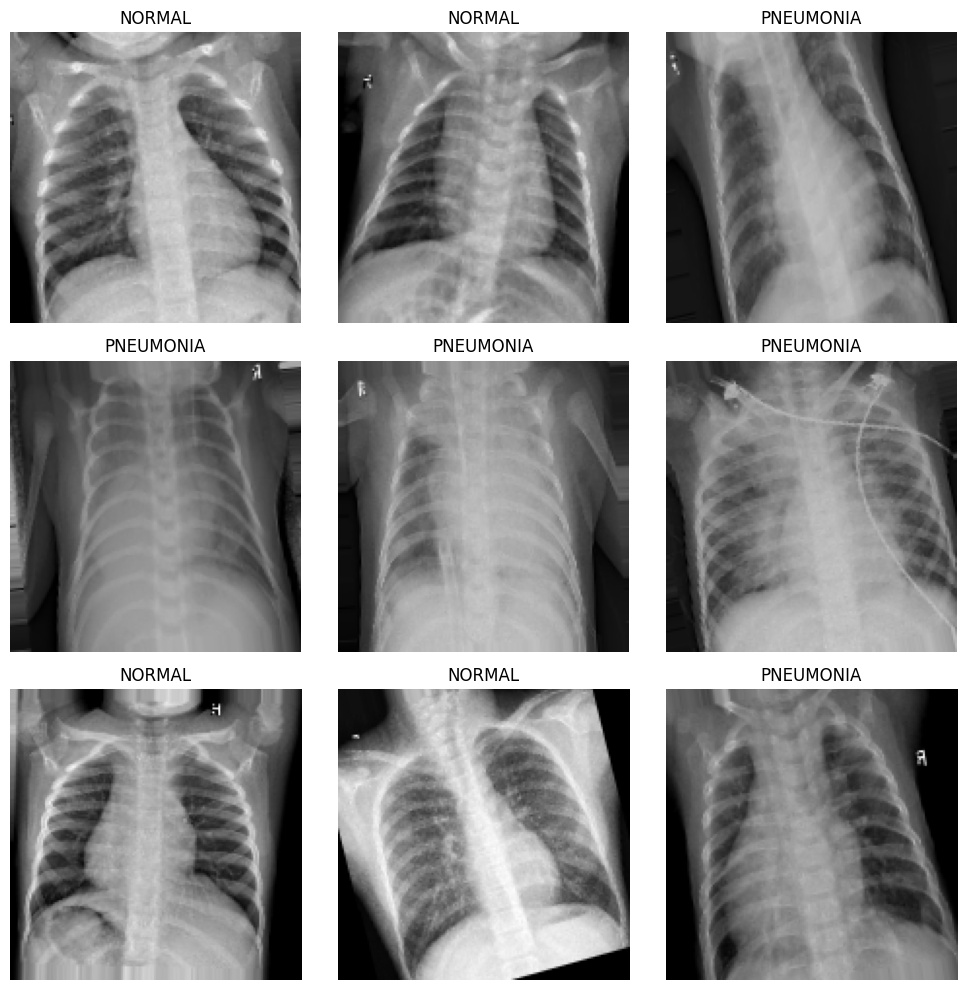

In [ ]:
# Get one batch of images and labels
images, labels = next(train_gen)

class_names = {v: k for k, v in train_gen.class_indices.items()}

plt.figure(figsize=(10, 10))
for i in range(9):
    plt.subplot(3, 3, i+1)
    plt.imshow(images[i])
    plt.title(class_names[int(labels[i])])
    plt.axis('off')
plt.tight_layout()
plt.show()

## Step 6: Build the CNN Model (Layer by Layer)

Each block below follows the standard CNN architecture:
**Convolution -> ReLU Activation -> Max Pooling**

Repeated blocks allow the network to learn increasingly complex features
(edges -> textures -> shapes -> patterns specific to pneumonia).

In [ ]:
model = models.Sequential()

# ---------------------------------------------------
# 1. INPUT LAYER
# The input shape is defined inside the first Conv2D layer.
# Each image is 150x150 pixels with 3 color channels (RGB).
# ---------------------------------------------------

# ---------------------------------------------------
# 2 & 3. CONVOLUTION LAYER + RELU ACTIVATION (Block 1)
# 32 filters of size 3x3 extract low-level features (edges, lines)
# ---------------------------------------------------
model.add(layers.Conv2D(32, (3, 3), activation='relu', input_shape=(150, 150, 3)))

# ---------------------------------------------------
# 4. POOLING LAYER (Max Pooling)
# Reduces the spatial size of the feature maps by half,
# keeping only the most important information.
# ---------------------------------------------------
model.add(layers.MaxPooling2D(2, 2))

# ---------------------------------------------------
# CONV + RELU + POOLING (Block 2)
# 64 filters extract more detailed features
# ---------------------------------------------------
model.add(layers.Conv2D(64, (3, 3), activation='relu'))
model.add(layers.MaxPooling2D(2, 2))

# ---------------------------------------------------
# CONV + RELU + POOLING (Block 3)
# 128 filters extract even more complex/deeper features
# ---------------------------------------------------
model.add(layers.Conv2D(128, (3, 3), activation='relu'))
model.add(layers.MaxPooling2D(2, 2))

# ---------------------------------------------------
# CONV + RELU + POOLING (Block 4)
# Another 128 filters to extract high-level patterns
# ---------------------------------------------------
model.add(layers.Conv2D(128, (3, 3), activation='relu'))
model.add(layers.MaxPooling2D(2, 2))

# ---------------------------------------------------
# FLATTEN LAYER
# Converts the 2D feature maps into a 1D vector
# so it can be fed into the Fully Connected (Dense) layers.
# ---------------------------------------------------
model.add(layers.Flatten())

# ---------------------------------------------------
# DROPOUT LAYER
# Randomly disables 50% of neurons during training
# to reduce overfitting.
# ---------------------------------------------------
model.add(layers.Dropout(0.5))

# ---------------------------------------------------
# 5. FULLY CONNECTED LAYER (Dense + ReLU)
# Combines all extracted features to learn the final
# classification decision boundary.
# ---------------------------------------------------
model.add(layers.Dense(512, activation='relu'))

# ---------------------------------------------------
# 6. OUTPUT LAYER
# A single neuron with Sigmoid activation outputs a
# probability between 0 and 1:
#   - Close to 0 -> NORMAL
#   - Close to 1 -> PNEUMONIA
# ---------------------------------------------------
model.add(layers.Dense(1, activation='sigmoid'))

# Display the full model architecture
model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 15, 15, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     3,211,776 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           513 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,453,121 (13.17 MB)

 Trainable params: 3,453,121 (13.17 MB)

 Non-trainable params: 0 (0.00 B)

## Step 7: Compile the Model

- **Optimizer:** Adam (adjusts weights to minimize loss)
- **Loss function:** Binary Crossentropy (since we have 2 classes: NORMAL vs PNEUMONIA)
- **Metric:** Accuracy

In [ ]:
# model.compile(
#     optimizer='adam'(learning_rate=0.0001),
#     loss='binary_crossentropy',
#     metrics=['accuracy']
# )

from tensorflow.keras.optimizers import Adam

model.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)


## Step 8: Train the Model

The model is trained for a number of epochs.
Training accuracy/loss and validation accuracy/loss are tracked after each epoch.

In [ ]:
# from tensorflow.keras.callbacks import EarlyStopping

# early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

# history = model.fit(
#     train_gen,
#     validation_data=val_gen,
#     epochs=50,   # increase number of epochs
#     callbacks=[early_stop]
# )

# epochs = 10

# history = model.fit(
#     train_gen,
#     validation_data=val_gen,
#     epochs=epochs
# )

from tensorflow.keras.callbacks import EarlyStopping
from sklearn.utils import class_weight
import numpy as np

# Automatically calculate weights based on class imbalance
weights = class_weight.compute_class_weight(
    class_weight='balanced',
    classes=np.unique(train_gen.classes),
    y=train_gen.classes
)
class_weights = dict(enumerate(weights))
print("Class weights:", class_weights)


early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

history = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=50,   # increase number of epochs
    class_weight=class_weights,  # <-- yeh add karo
    callbacks=[early_stop]
)


Class weights: {0: np.float64(1.9445479962721341), 1: np.float64(0.6730645161290323)}
Epoch 1/50
131/131 ━━━━━━━━━━━━━━━━━━━━ 86s 599ms/step - accuracy: 0.7012 - loss: 0.5188 - val_accuracy: 0.8466 - val_loss: 0.3741
Epoch 2/50
131/131 ━━━━━━━━━━━━━━━━━━━━ 71s 546ms/step - accuracy: 0.8687 - loss: 0.3020 - val_accuracy: 0.9060 - val_loss: 0.2237
Epoch 3/50
131/131 ━━━━━━━━━━━━━━━━━━━━ 70s 531ms/step - accuracy: 0.9032 - loss: 0.2332 - val_accuracy: 0.7737 - val_loss: 0.5611
Epoch 4/50
131/131 ━━━━━━━━━━━━━━━━━━━━ 67s 514ms/step - accuracy: 0.9106 - loss: 0.2113 - val_accuracy: 0.9185 - val_loss: 0.2011
Epoch 5/50
131/131 ━━━━━━━━━━━━━━━━━━━━ 67s 514ms/step - accuracy: 0.9164 - loss: 0.1964 - val_accuracy: 0.9319 - val_loss: 0.1760
Epoch 6/50
131/131 ━━━━━━━━━━━━━━━━━━━━ 74s 565ms/step - accuracy: 0.9250 - loss: 0.1885 - val_accuracy: 0.9281 - val_loss: 0.1586
Epoch 7/50
131/131 ━━━━━━━━━━━━━━━━━━━━ 67s 510ms/step - accuracy: 0.9248 - loss: 0.1844 - val_accuracy: 0.9415 - val_loss: 0.15

## Step 9: Evaluate the Model on Test Data

Check how well the trained model performs on completely unseen test images.

In [ ]:
test_loss, test_acc = model.evaluate(test_gen)
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")

20/20 ━━━━━━━━━━━━━━━━━━━━ 6s 278ms/step - accuracy: 0.8766 - loss: 0.3431
Test Loss: 0.3431
Test Accuracy: 0.8766


## Step 10: Plot Training History (Accuracy & Loss Graphs)

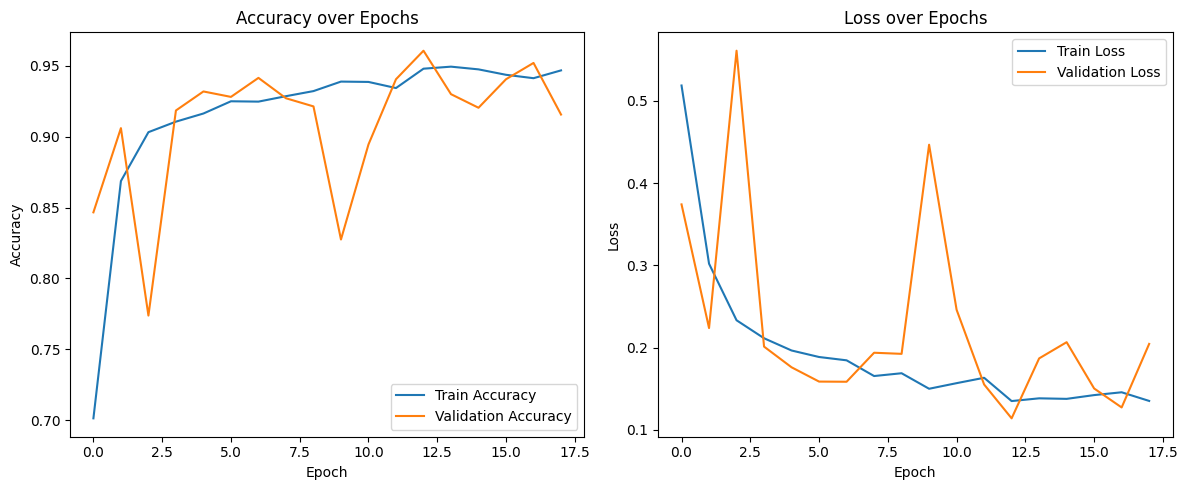

In [ ]:
# Accuracy graph
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Accuracy over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# Loss graph
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Loss over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

## Step 11: Confusion Matrix and Classification Report

This gives a detailed breakdown of model performance:
Precision, Recall, F1-score for each class.

20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 192ms/step


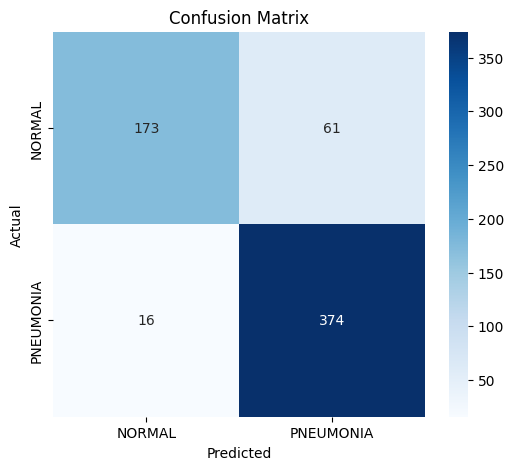

              precision    recall  f1-score   support

      NORMAL       0.92      0.74      0.82       234
   PNEUMONIA       0.86      0.96      0.91       390

    accuracy                           0.88       624
   macro avg       0.89      0.85      0.86       624
weighted avg       0.88      0.88      0.87       624



In [ ]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

# Get true labels
true_labels = test_gen.classes

# Get model predictions (probabilities)
predictions = model.predict(test_gen)

# Convert probabilities to class labels (0 or 1) using 0.5 threshold
predicted_labels = (predictions > 0.55).astype(int).flatten()

# Confusion Matrix
cm = confusion_matrix(true_labels, predicted_labels)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names.values(),
            yticklabels=class_names.values())
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

# Classification Report
print(classification_report(true_labels, predicted_labels, target_names=class_names.values()))

## Step 13: Save the Model (Optional)

Save the trained model so it can be reloaded later without retraining.

In [ ]:
model.save("pneumonia_cnn_model.keras")
files.download("pneumonia_cnn_model.keras")